In [1]:
import time, random, numpy as np, torch
import torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt

# Reproductibilité
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Device: cuda
Tesla T4


In [2]:
import os
for root, _, files in os.walk("/kaggle/input"):
    for f in files: print(os.path.join(root, f))

/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images.idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels.idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-images.idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-labels.idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-images-idx3-ubyte/train-images-idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-labels-idx1-ubyte/train-labels-idx1-ubyte


In [4]:
import struct

PATH = "/kaggle/input/datasets/hojjatk/mnist-dataset"

def read_idx_images(path):
    with open(path, "rb") as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(n, rows, cols)

def read_idx_labels(path):
    with open(path, "rb") as f:
        magic, n = struct.unpack(">II", f.read(8))
        return np.frombuffer(f.read(), dtype=np.uint8)

X_train = read_idx_images(f"{PATH}/train-images-idx3-ubyte/train-images-idx3-ubyte")
y_train = read_idx_labels(f"{PATH}/train-labels-idx1-ubyte/train-labels-idx1-ubyte")
X_test  = read_idx_images(f"{PATH}/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte")
y_test  = read_idx_labels(f"{PATH}/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte")
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


In [6]:
from torch.utils.data import random_split

class MNISTDataset(Dataset):
    def __init__(self, X, y):
        X = torch.tensor(X, dtype=torch.float32).unsqueeze(1) / 255.0
        self.X = (X - 0.1307) / 0.3081          # normalisation MNIST
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]

full_train = MNISTDataset(X_train, y_train)
test_ds    = MNISTDataset(X_test, y_test)
train_ds, val_ds = random_split(full_train, [54000, 6000],
                                generator=torch.Generator().manual_seed(SEED))

BATCH = 128
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)

In [7]:
class CNN(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1),   # 28x28
            nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),                                        # 14x14
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),  # 14x14
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),                                        # 7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 10),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = CNN().to(device)
print(model)
print("Paramètres :", sum(p.numel() for p in model.parameters()))

CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Paramètres : 421834


In [8]:
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, preds, labels = 0.0, [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * x.size(0)
            preds.append(out.argmax(1).cpu()); labels.append(y.cpu())
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return (total_loss / len(labels),
            accuracy_score(labels, preds),
            f1_score(labels, preds, average="macro"),
            preds, labels)

def fit(model, epochs=10, lr=1e-3, wd=1e-4):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for ep in range(epochs):
        model.train(); running = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward(); optimizer.step()
            running += loss.item() * x.size(0)
        v_loss, v_acc, v_f1, _, _ = evaluate(model, val_loader, criterion)
        history["train_loss"].append(running / len(train_ds))
        history["val_loss"].append(v_loss); history["val_acc"].append(v_acc)
        print(f"Epoch {ep+1:2d}/{epochs} | train loss {history['train_loss'][-1]:.4f} "
              f"| val loss {v_loss:.4f} | val acc {v_acc:.4f} | val F1 {v_f1:.4f}")
    if device.type == "cuda": torch.cuda.synchronize()
    return history, time.time() - t0

history, train_time = fit(model, epochs=10)
print(f"Temps d'entraînement : {train_time:.1f} s")

Epoch  1/10 | train loss 0.1706 | val loss 0.0678 | val acc 0.9803 | val F1 0.9803
Epoch  2/10 | train loss 0.0650 | val loss 0.0588 | val acc 0.9837 | val F1 0.9835
Epoch  3/10 | train loss 0.0501 | val loss 0.0546 | val acc 0.9833 | val F1 0.9832
Epoch  4/10 | train loss 0.0438 | val loss 0.0423 | val acc 0.9863 | val F1 0.9862
Epoch  5/10 | train loss 0.0350 | val loss 0.0404 | val acc 0.9895 | val F1 0.9894
Epoch  6/10 | train loss 0.0323 | val loss 0.0376 | val acc 0.9875 | val F1 0.9873
Epoch  7/10 | train loss 0.0267 | val loss 0.0416 | val acc 0.9877 | val F1 0.9876
Epoch  8/10 | train loss 0.0270 | val loss 0.0320 | val acc 0.9908 | val F1 0.9907
Epoch  9/10 | train loss 0.0262 | val loss 0.0347 | val acc 0.9897 | val F1 0.9895
Epoch 10/10 | train loss 0.0230 | val loss 0.0382 | val acc 0.9910 | val F1 0.9909
Temps d'entraînement : 22.6 s


TEST | loss 0.0289 | acc 0.9904 | F1 0.9903


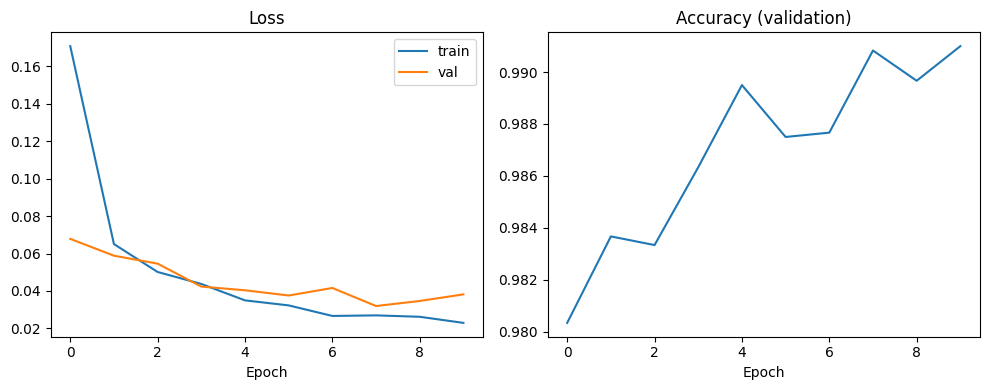

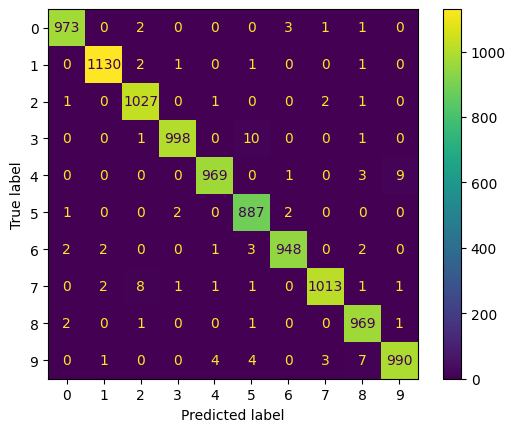

In [9]:
criterion = nn.CrossEntropyLoss()
t_loss, t_acc, t_f1, preds, labels = evaluate(model, test_loader, criterion)
print(f"TEST | loss {t_loss:.4f} | acc {t_acc:.4f} | F1 {t_f1:.4f}")

results = {}
results["CNN"] = {"accuracy": t_acc, "f1": t_f1, "loss": t_loss, "time_s": train_time}

# Courbes
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="train"); plt.plot(history["val_loss"], label="val")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history["val_acc"]); plt.title("Accuracy (validation)"); plt.xlabel("Epoch")
plt.tight_layout(); plt.savefig("cnn_curves.png", dpi=150); plt.show()

# Matrice de confusion
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(labels, preds)
plt.savefig("cnn_confusion.png", dpi=150); plt.show()

# Sauvegarde pour la comparaison finale
import json
json.dump(results, open("results_cnn.json", "w"), indent=2)
torch.save(model.state_dict(), "cnn_mnist.pth")